# YOLOv8 Train (Lokal) — Training asv

Train YOLOv8 dengan dataset **lokal** (hasil `tools/camera_capture.py`) tanpa hardcode Roboflow. Cocok export ONNX → dipakai Repo A/Repo B.

In [1]:
import os
HOME = os.getcwd()
print("CWD:", HOME)
print("Dataset path contoh:", os.path.join(HOME, "dataset", "data.yaml"))

CWD: /home/ibnu/Downloads/URDC/training asv/notebooks
Dataset path contoh: /home/ibnu/Downloads/URDC/training asv/notebooks/dataset/data.yaml


## Install ultralytics (training)
Jalankan hanya kalau belum: `pip install -r requirements-train.txt`

In [2]:
# from ultralytics import YOLO
# !pip install ultralytics==8.2.103 -q

In [3]:
from ultralytics import YOLO
from IPython.display import Image, display

## Opsi: dataset dari Roboflow (kalau tidak capture lokal)

Kalau dataset sudah dianotasi di Roboflow: isi `RF_*` di bawah, set `USE_ROBOFLOW = True`, lalu jalankan cell berikutnya.
Hasil unduhan (format YOLOv8) masuk ke folder `dataset/`.

Tautan/identitas dataset ada di URL dashboard: `app.roboflow.com/<workspace>/<project>/<versi>`.

**Jangan tulis API key di notebook.** Set lewat env: `export ROBOFLOW_API_KEY=xxxx`
(Windows: `setx ROBOFLOW_API_KEY xxxx`, lalu restart terminal).

> Alternatif tanpa SDK: dashboard Roboflow -> *Download Dataset* -> format **YOLOv8**,
> unduh zip lalu ekstrak isinya ke folder `dataset/`.

> Capture lokal? Lewati saja cell di bawah (`USE_ROBOFLOW = False`).

In [4]:
# --- OPSIONAL: unduh dataset ber-anotasi dari Roboflow ---
ROBOFLOW_API_KEY = os.environ.get("ROBOFLOW_API_KEY", "")
RF_WORKSPACE = "ardis-workspace-ljcds"   # dari URL: app.roboflow.com/<workspace>/<project>/<versi>
RF_PROJECT   = "pod_detection"
RF_VERSION   = 1
USE_ROBOFLOW = False                     # True = unduh dari cloud, False = pakai dataset/ lokal

if USE_ROBOFLOW:
    assert ROBOFLOW_API_KEY, "set env ROBOFLOW_API_KEY dulu (jangan hardcode di notebook)"
    !pip install roboflow --quiet
    from roboflow import Roboflow
    version = (Roboflow(api_key=ROBOFLOW_API_KEY)
               .workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION))
    version.download("yolov8", location="dataset")
    print("Roboflow dataset ->", version.location)
else:
    print("Lewati Roboflow - pakai dataset/ lokal hasil tools/camera_capture.py")


Lewati Roboflow - pakai dataset/ lokal hasil tools/camera_capture.py


## Pilih model + data

In [5]:
DATA = os.path.join(os.path.dirname(HOME) if "notebooks" in HOME else HOME, "dataset", "data.yaml")
DATA = os.path.join("/home/ibnu/Downloads/URDC/training asv", "dataset", "data.yaml") if not os.path.exists(DATA) else DATA
assert os.path.exists(DATA), (
    f"data.yaml tidak ada: {DATA}\n"
    "-> capture lokal (tools/camera_capture.py) ATAU aktifkan USE_ROBOFLOW di cell atas")
MODEL = "yolov8n.pt"
EPOCHS = 50
IMGSZ = 640
print("DATA:", DATA)


DATA: /home/ibnu/Downloads/URDC/training asv/dataset/data.yaml


## Train

In [6]:
model = YOLO(MODEL)
results = model.train(data=DATA, epochs=EPOCHS, imgsz=IMGSZ, plots=True)
best = os.path.join(HOME, "runs", "detect", "train", "weights", "best.pt")
print("BEST:", best)

Ultralytics 8.4.182 🚀 Python-3.14.8 torch-2.14.1+cpu CPU (11th Gen Intel Core i3-1115G4 @ 3.00GHz)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/ibnu/Downloads/URDC/training asv/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-5, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.3it/s 0.1s

                   all          1          1    0.00333          1    0.00696    0.00392


Speed: 1.2ms preprocess, 118.2ms inference, 0.0ms loss, 11.9ms postprocess per image


Results saved to /home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/train-5


BEST: /home/ibnu/Downloads/URDC/training asv/notebooks/runs/detect/train/weights/best.pt


## Hasil training

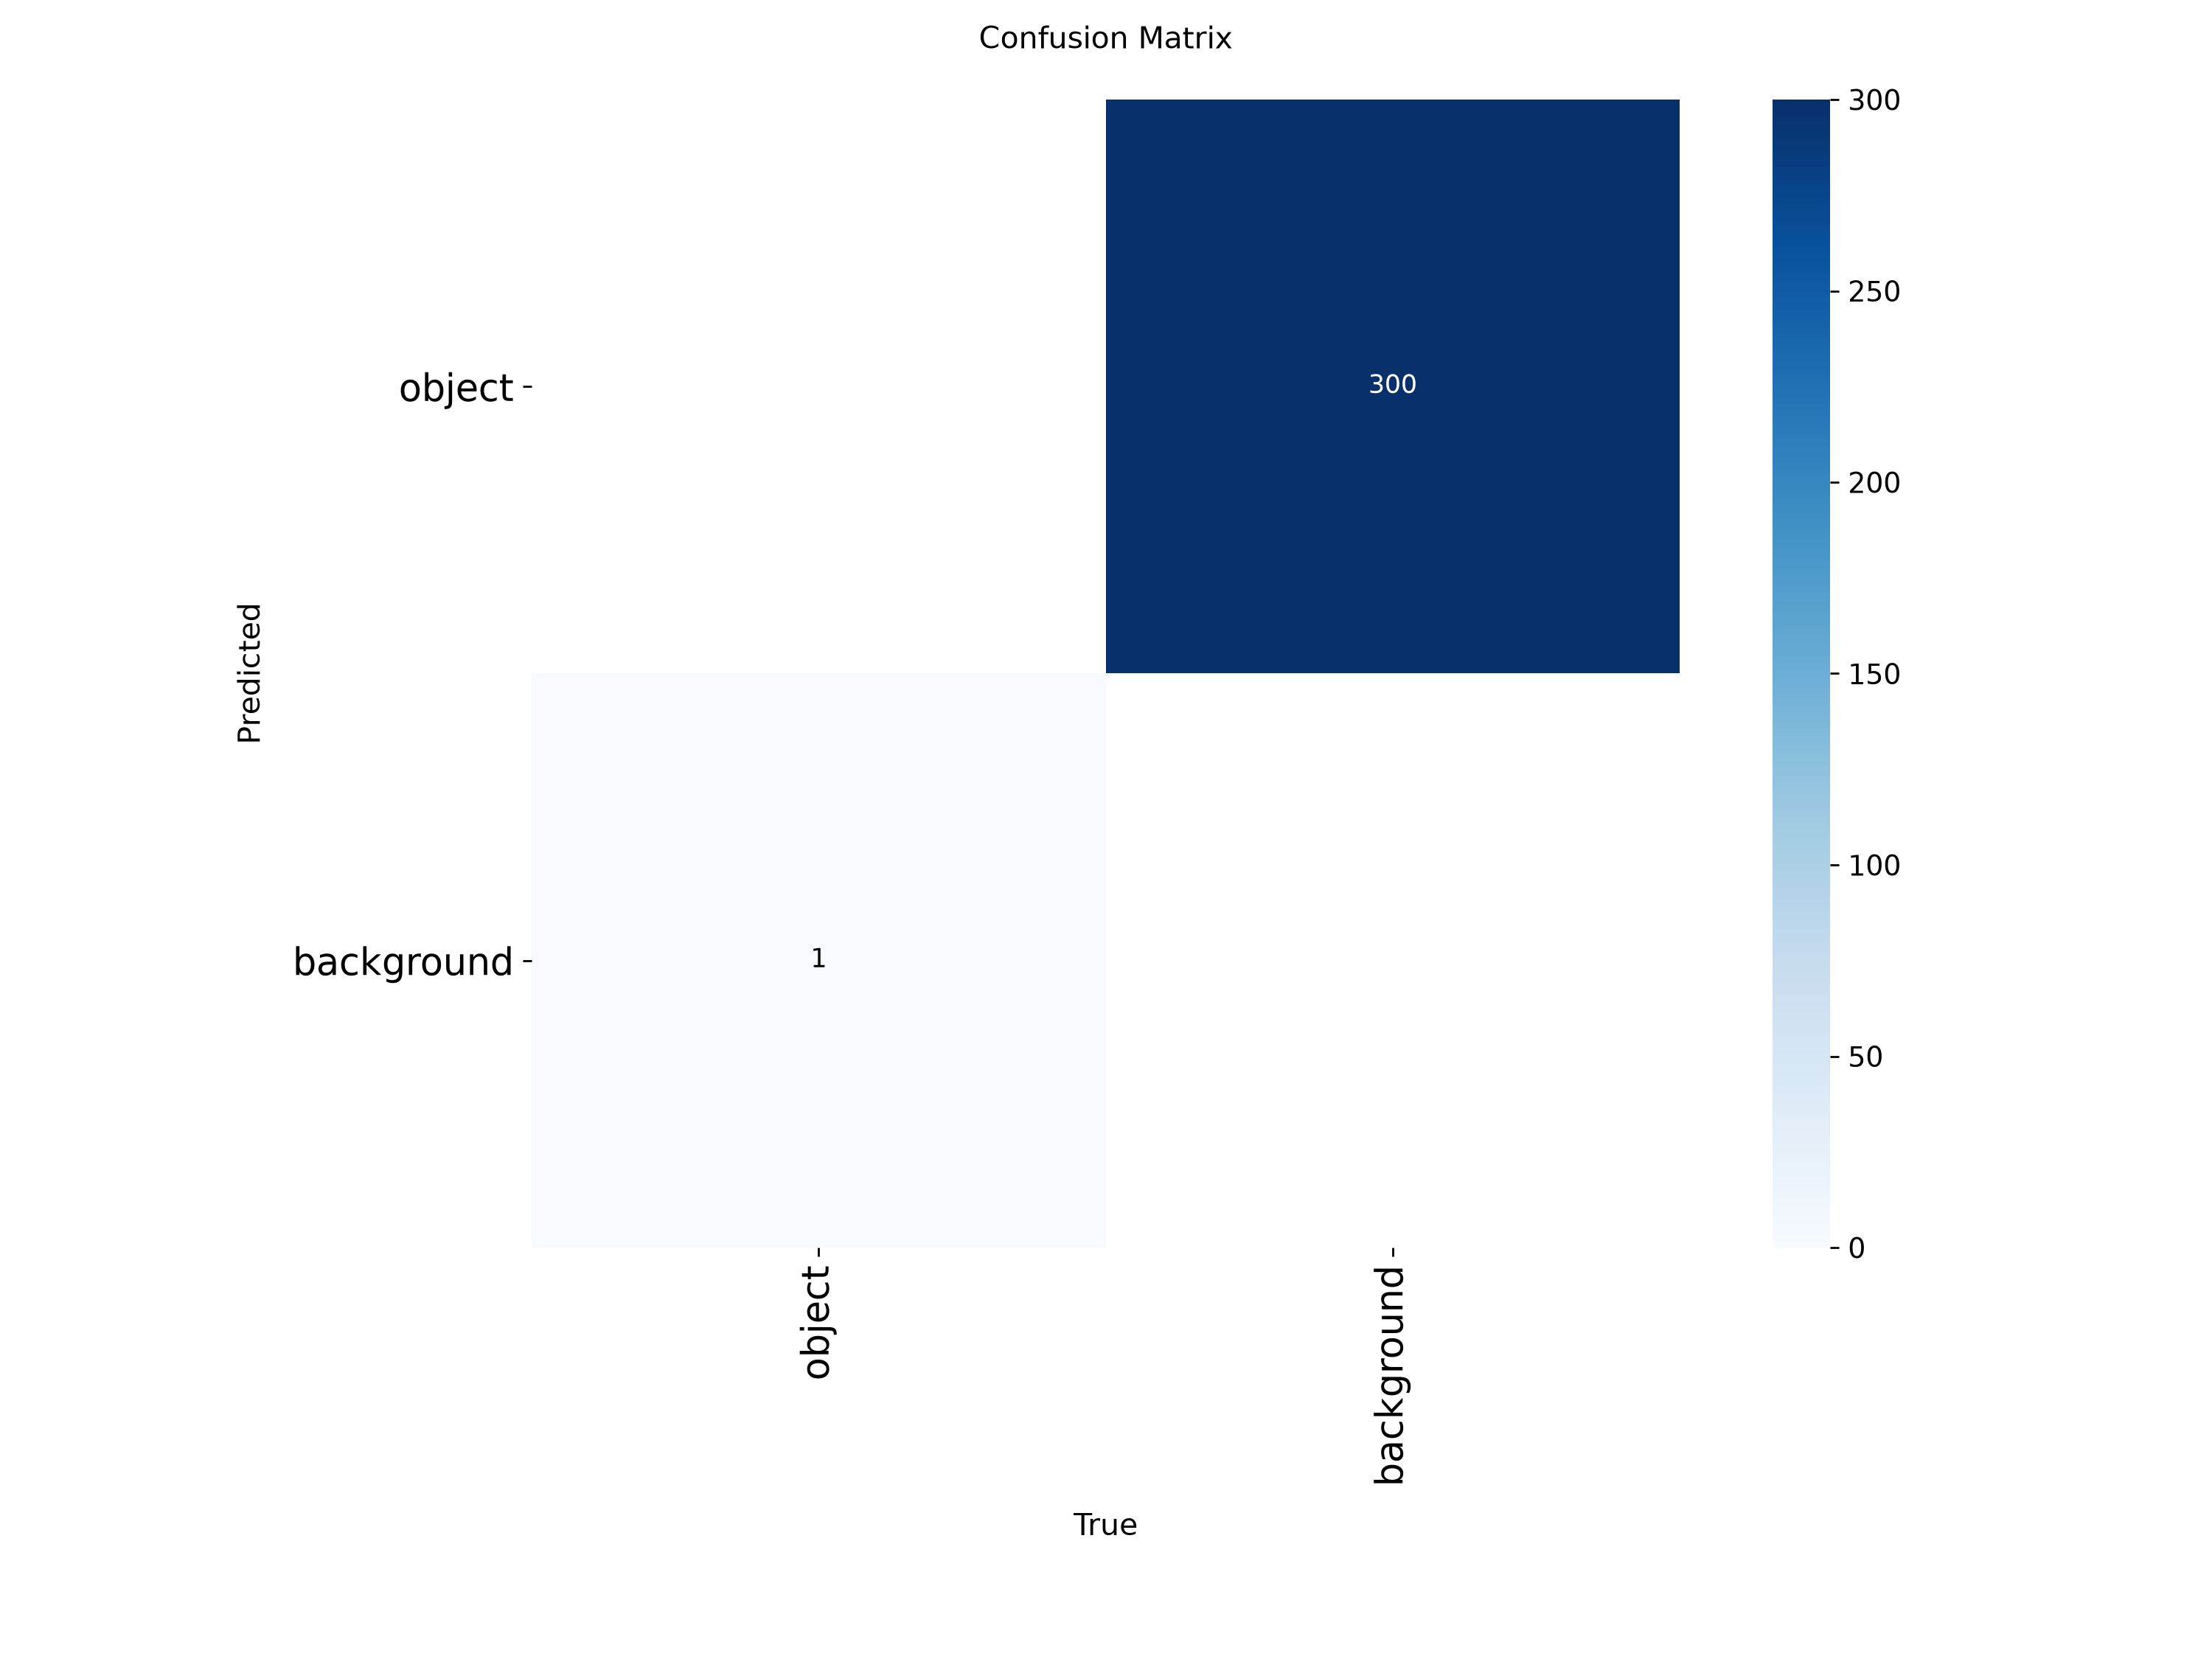

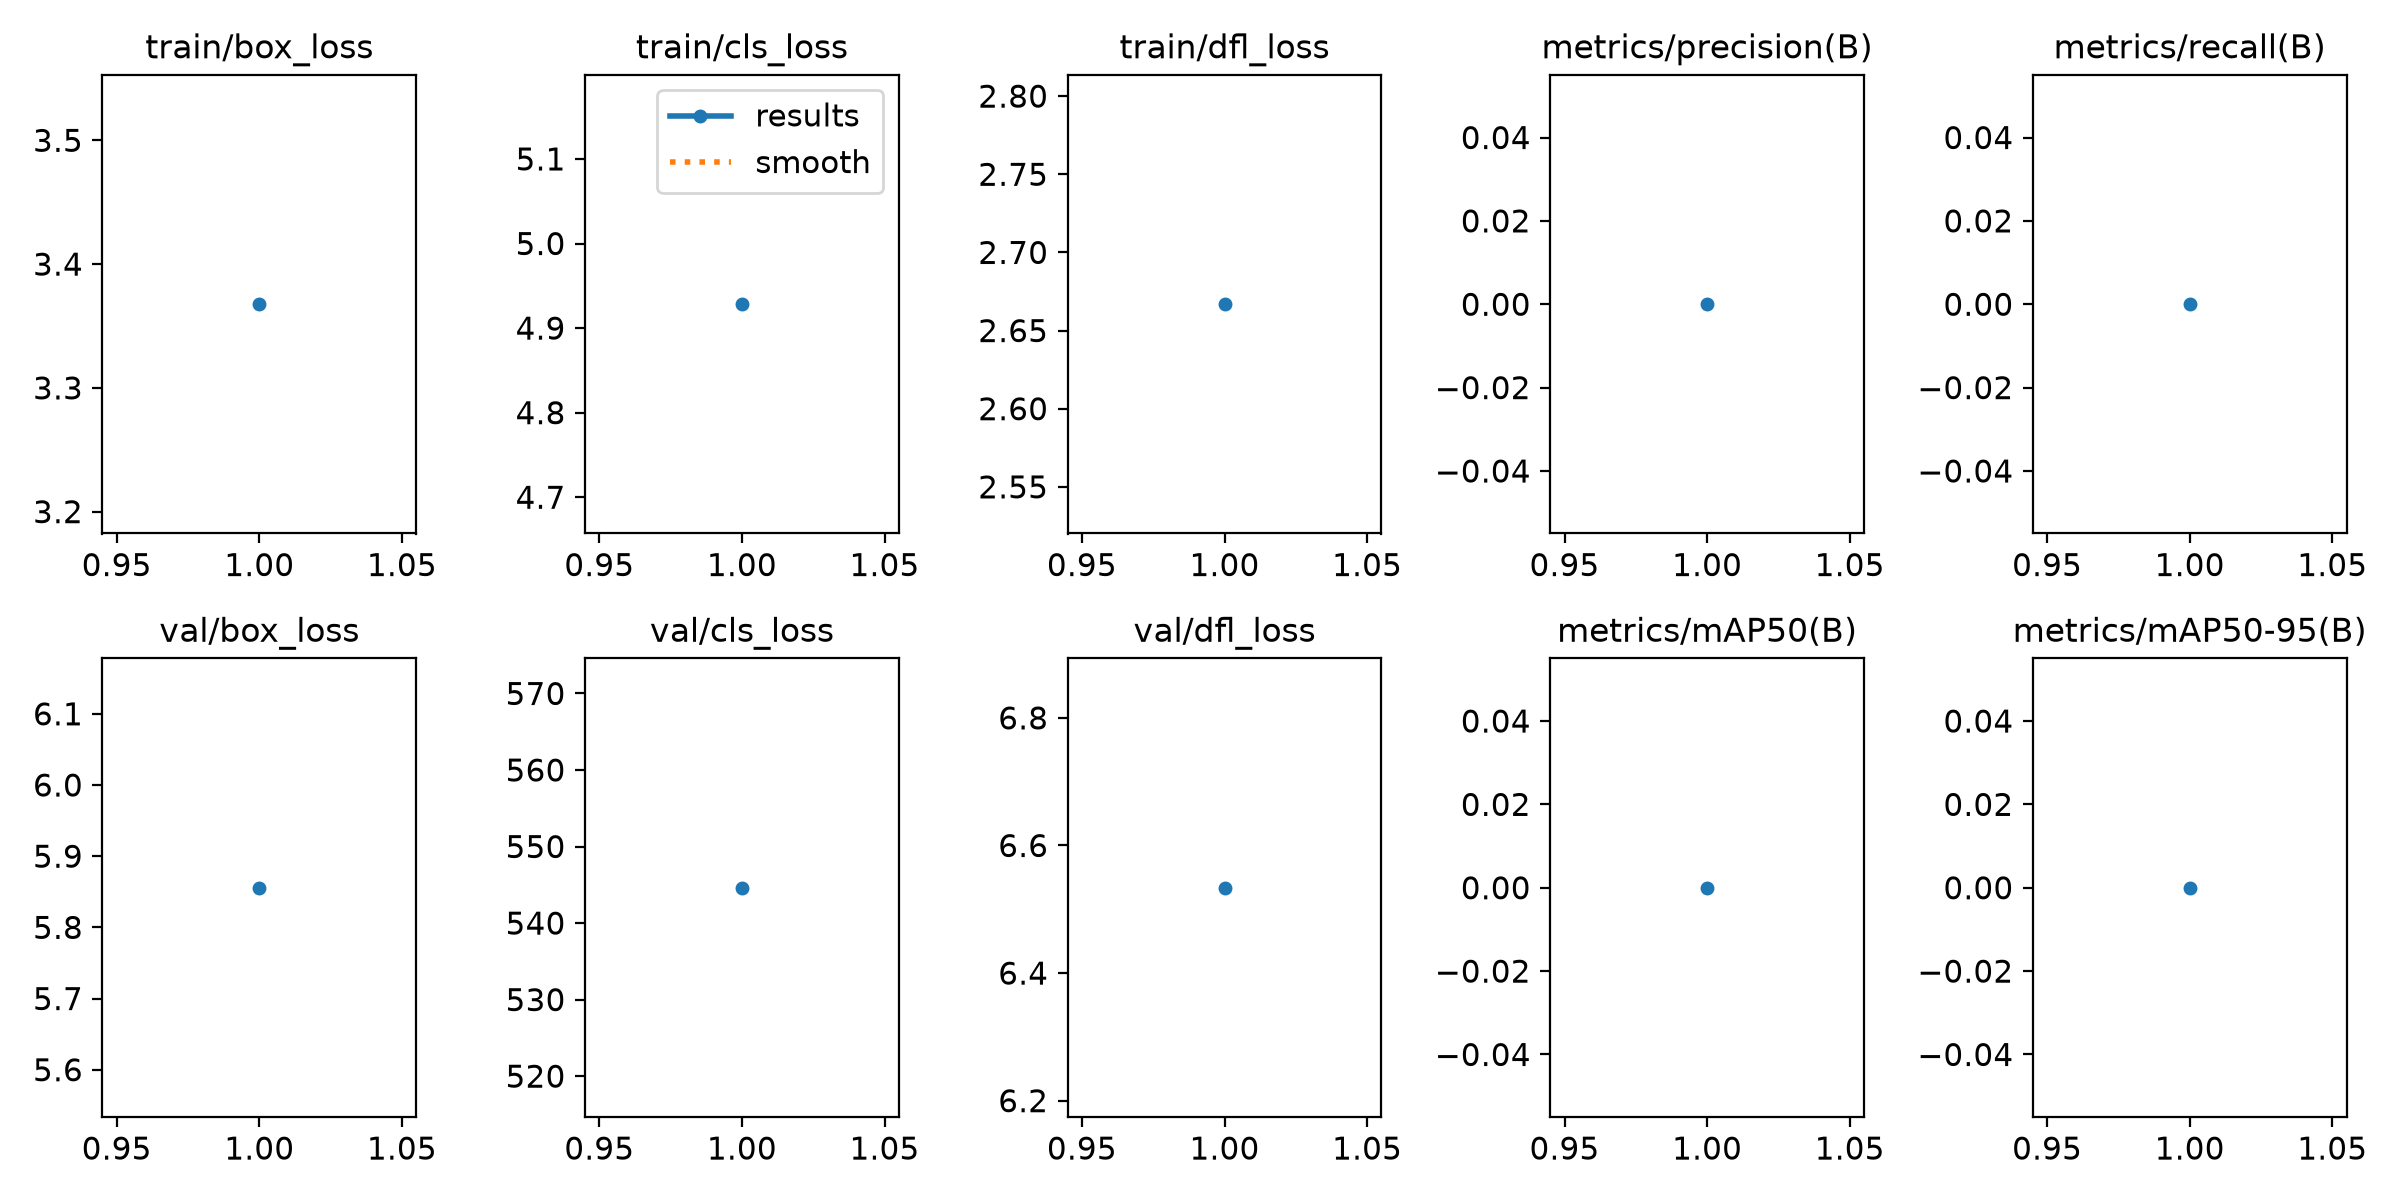

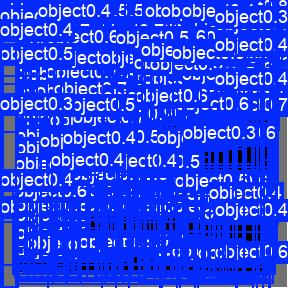

In [7]:
import os
RUNS = '/home/ibnu/Downloads/URDC/training asv/runs/detect/train'
display(Image(filename=os.path.join(RUNS,'confusion_matrix.png'), width=600))
display(Image(filename=os.path.join(RUNS,'results.png'), width=600))
display(Image(filename=os.path.join(RUNS,'val_batch0_pred.jpg'), width=600))


## Validasi

In [8]:
model.val(data=DATA, model=best)

Ultralytics 8.4.182 🚀 Python-3.14.8 torch-2.14.1+cpu CPU (11th Gen Intel Core i3-1115G4 @ 3.00GHz)


Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 131.3±0.0 MB/s, size: 6.9 KB)


val: Scanning /home/ibnu/Downloads/URDC/training asv/dataset/labels/val.cache... 1 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1/1 419.4Kit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 9.7it/s 0.1s

                   all          1          1    0.00333          1    0.00696    0.00392


Speed: 1.3ms preprocess, 85.2ms inference, 0.0ms loss, 11.3ms postprocess per image


Results saved to /home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/val


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f6542df5c50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## ONNX untuk kapal, PT untuk Python

Training di cell **Train** sudah otomatis menghasilkan **`runs/detect/train/weights/best.pt`** —
itu model aslinya. `best.pt` dipakai untuk `model.predict(...)`, training lanjutan, atau `yolo` CLI.

Masalahnya `best.pt` **tidak bisa dibaca `cv2.dnn`** (yang dipakai Repo A/Repo B). Karena itu bobot
yang sama diekspor ke **ONNX**: isinya identik, cuma formatnya bisa dibuka OpenCV.

| Ingin | Yang dilakukan |
|---|---|
| Pakai `.pt` saja | Lewati cell di bawah — `best.pt` sudah jadi |
| Dipakai kapal (Repo A/B, `cv2.dnn`) | Jalankan cell di bawah (ekspor ONNX) |
| Dua-duanya | Jalankan semua — dapat `best.pt` **dan** `best.onnx` |

Jadi kalau cuma butuh `.pt`, **tidak perlu mengubah apa pun** — cukup jangan jalankan cell ekspor ini.

In [9]:
from shutil import copy2

# best.pt SUDAH ada hasil training — tidak dibuat ulang di sini
print("PT  :", best)

# ekspor ke ONNX (format yang bisa dibaca cv2.dnn di Repo A/Repo B)
onnx_out = model.export(format="onnx", opset=12, simplify=True)
print("ONNX:", onnx_out)

# kumpulkan hasilnya di weights/ biar gampang dicopy ke repo kapal
os.makedirs(os.path.join(HOME, "weights"), exist_ok=True)
dst = os.path.join(HOME, "weights", os.path.basename(str(onnx_out)))
copy2(str(onnx_out), dst)
print("disalin ke:", dst)


PT  : /home/ibnu/Downloads/URDC/training asv/notebooks/runs/detect/train/weights/best.pt
Ultralytics 8.4.182 🚀 Python-3.14.8 torch-2.14.1+cpu CPU (11th Gen Intel Core i3-1115G4 @ 3.00GHz)


Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs



PyTorch: starting from '/home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/train-5/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)


requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/8.9 MB ? eta -:--:--
   ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/8.9 MB 7.0 MB/s eta 0:00:02
   ━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/8.9 MB 7.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━ 3.9/8.9 MB 7.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━ 5.5/8.9 MB 7.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━ 6.8/8.9 MB 7.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━ 8.1/8.9 MB 7.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 7.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/23.8 MB ? eta -:--:--
   ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/23.8 MB 7.6 MB/s eta 0:00:03
   ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/23.8 MB 7.4 MB/s eta 0:00:03
   ━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/23.8 MB 7.3 MB/s eta 0:00:03
   ━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/23.8 MB 7.3 MB/s eta 0:00:03
   ━━━━━━━━━━━━╸━━━━━━━━

...


ONNX: starting export with onnx 1.23.2 opset 12...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success ✅ 9.2s, saved as '/home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/train-5/weights/best.onnx' (12.2 MB)



Export complete (9.3s)
Results saved to /home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/train-5/weights/best.onnx
Predict:         yolo predict task=detect model=/home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/train-5/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/train-5/weights/best.onnx imgsz=640 data=/home/ibnu/Downloads/URDC/training asv/dataset/data.yaml 
Visualize:       https://netron.app


ONNX: /home/ibnu/Downloads/URDC/usluk-usluk/runs/detect/train-5/weights/best.onnx
disalin ke: /home/ibnu/Downloads/URDC/training asv/notebooks/weights/best.onnx
